<a href="https://colab.research.google.com/github/swanandkulkarni10-bot/AI-MidSem-/blob/main/swanand_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Step 1: Setup and First Look
Goal: Load the data and understand its shape, types, and gaps.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# SET plotting style and default figure size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# df = READ CSV("train.csv")
# Note: Make sure 'train.csv' exists in your path. If you are using california_housing_train.csv, change the path below.
try:
    df = pd.read_csv("train.csv")
except FileNotFoundError:
    # Fallback to sample data if train.csv is not present
    df = pd.read_csv("/content/sample_data/california_housing_train.csv")
    print("Warning: 'train.csv' not found. Loaded 'california_housing_train.csv' instead.\n")

# PRINT shape of df
print("Shape of df:", df.shape)
print("-" * 40)

# PRINT first 5 rows
print("First 5 rows:")
display(df.head())
print("-" * 40)

# PRINT info (column names, dtypes, non-null counts)
print("DataFrame Info:")
df.info()
print("-" * 40)

# missing = COUNT null values per column
# SORT missing descending
# PRINT columns where missing > 0 with percentage
missing_count = df.isnull().sum()
missing_percent = 100 * df.isnull().sum() / len(df)
missing_df = pd.concat([missing_count, missing_percent], axis=1, keys=['Missing Count', 'Percent'])
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

if not missing_df.empty:
    print("Columns with missing values:")
    print(missing_df)
else:
    print("No missing values found in any column.")


Shape of df: (17000, 9)
----------------------------------------
First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


----------------------------------------
DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB
----------------------------------------
No missing values found in any column.


Step 2: Classify V ariables
Goal: Split columns into numerical, categorical, and ordinal groups.

In [4]:
import pandas as pd
import numpy as np

# 1. Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. Define ordinal category order mapping
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert specified columns to ordered categorical if they exist in df
for col, categories in ordinal_map.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=categories, ordered=True)

# 3. Build a summary table
summary_data = []
for col in df.columns:
    col_type = str(df[col].dtype)
    num_unique = df[col].nunique()
    # Safely get up to 3 example values
    example_vals = df[col].dropna().unique()[:3].tolist()
    summary_data.append({
        "Column Name": col,
        "Type": col_type,
        "Unique Values Count": num_unique,
        "Example Values": example_vals
    })

summary_df = pd.DataFrame(summary_data)

# 4. Display the table
display(summary_df)

,Column Name,Type,Unique Values Count,Example Values
0,longitude,float64,827,"[-114.31, -114.47, -114.56]"
1,latitude,float64,840,"[34.19, 34.4, 33.69]"
2,housing_median_age,float64,52,"[15.0, 19.0, 17.0]"
3,total_rooms,float64,5533,"[5612.0, 7650.0, 720.0]"
4,total_bedrooms,float64,1848,"[1283.0, 1901.0, 174.0]"
5,population,float64,3683,"[1015.0, 1129.0, 333.0]"
6,households,float64,1740,"[472.0, 463.0, 117.0]"
7,median_income,float64,11175,"[1.4936, 1.82, 1.6509]"
8,median_house_value,float64,3694,"[66900.0, 80100.0, 85700.0]"


Step 3: Descriptive Statistics
Goal: Summarise centre and spread.

In [6]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# 1. DISPLAY df.describe() for numeric columns
print("Descriptive Statistics for Numeric Columns:")
display(df.describe())
print("-" * 80)

# 2. Identify target numeric columns
# Use target columns from your pseudocode if they exist; otherwise fallback to available columns
target_numeric = ["SalePrice", "GrLivArea", "LotArea"]
actual_numeric = [col for col in target_numeric if col in df.columns]

if not actual_numeric:
    # Fallback columns from California Housing dataset
    actual_numeric = ["median_house_value", "total_rooms", "median_income"]
    print(f"Target columns {target_numeric} not found. Using fallback columns: {actual_numeric}\n")

# Calculate detailed metrics for each numeric column
for column in actual_numeric:
    col_data = df[column].dropna()
    if len(col_data) == 0:
        continue

    mean_val = col_data.mean()
    median_val = col_data.median()

    # Mode calculation using pandas
    mode_series = col_data.mode()
    mode_val = mode_series.iloc[0] if not mode_series.empty else np.nan

    std_val = col_data.std()
    var_val = col_data.var()
    val_range = col_data.max() - col_data.min()

    q75, q25 = np.percentile(col_data, [75, 25])
    iqr_val = q75 - q25

    skew_val = col_data.skew()
    kurt_val = col_data.kurtosis()

    print(f"--- Statistics for {column} ---")
    print(f"Mean:               {mean_val:.4f}")
    print(f"Median:             {median_val:.4f}")
    print(f"Mode:               {mode_val:.4f}")
    print(f"Std Dev:            {std_val:.4f}")
    print(f"Variance:           {var_val:.4f}")
    print(f"Range:              {val_range:.4f}")
    print(f"IQR:                {iqr_val:.4f}")
    print(f"Skewness:           {skew_val:.4f}")
    print(f"Kurtosis:           {kurt_val:.4f}")

    if mean_val > median_val:
        print("Note: Right skewed")
    elif mean_val < median_val:
        print("Note: Left skewed")
    else:
        print("Note: Perfectly symmetric")
    print()

print("-" * 80)

# 3. Identify target categorical columns
target_categorical = ["Neighborhood", "HouseStyle"]
actual_categorical = [col for col in target_categorical if col in df.columns]

if actual_categorical:
    for column in actual_categorical:
        print(f"--- Value Counts & Mode for {column} ---")
        print(df[column].value_counts())
        mode_series = df[column].mode()
        if not mode_series.empty:
            print(f"Mode: {mode_series.iloc[0]}")
        print()
else:
    print(f"None of the categorical columns {target_categorical} were found in the current DataFrame.")

Descriptive Statistics for Numeric Columns:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


--------------------------------------------------------------------------------
Target columns ['SalePrice', 'GrLivArea', 'LotArea'] not found. Using fallback columns: ['median_house_value', 'total_rooms', 'median_income']

--- Statistics for median_house_value ---
Mean:               207300.9124
Median:             180400.0000
Mode:               500001.0000
Std Dev:            115983.7644
Variance:           13452233601.4276
Range:              485002.0000
IQR:                145600.0000
Skewness:           0.9730
Kurtosis:           0.3040
Note: Right skewed

--- Statistics for total_rooms ---
Mean:               2643.6644
Median:             2127.0000
Mode:               1582.0000
Std Dev:            2179.9471
Variance:           4752169.2343
Range:              37935.0000
IQR:                1689.2500
Skewness:           4.0027
Kurtosis:           29.5159
Note: Right skewed

--- Statistics for median_income ---
Mean:               3.8836
Median:             3.5446
Mode:          

Step 4: Distributions
Goal: See the shape of the target and key features.

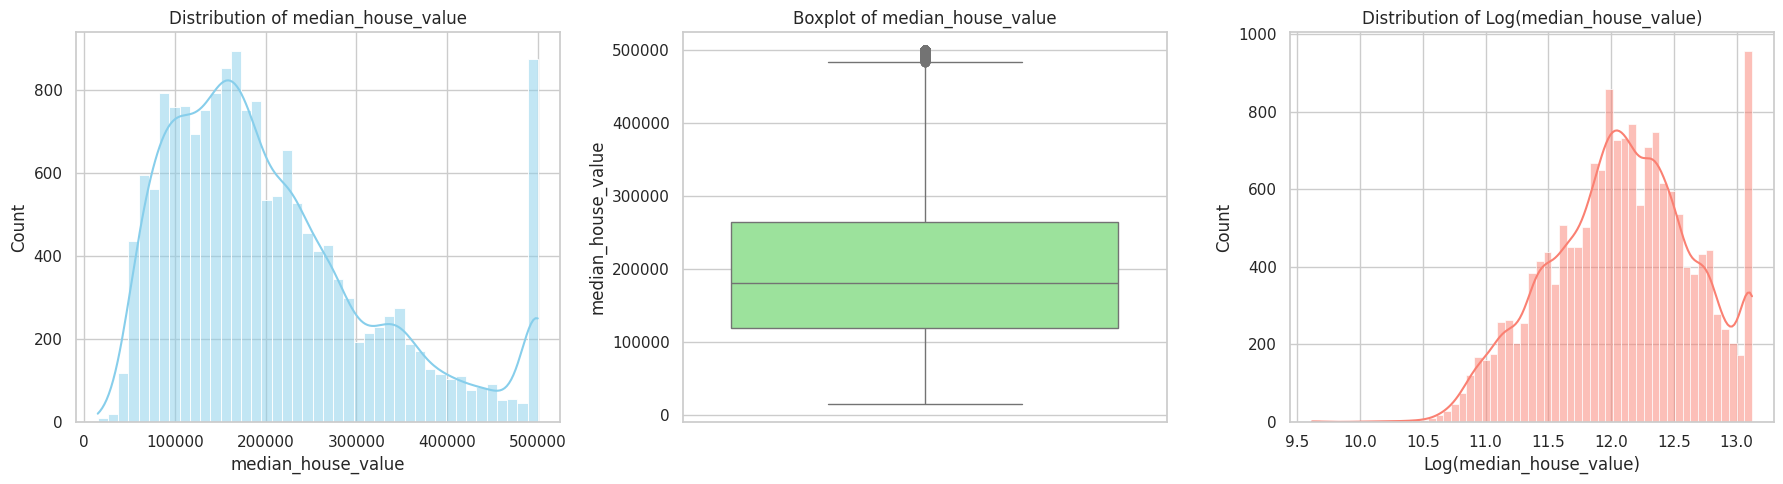

Skewness of original median_house_value: 0.9730
Skewness of Log(median_house_value):     -0.1786
--------------------------------------------------------------------------------


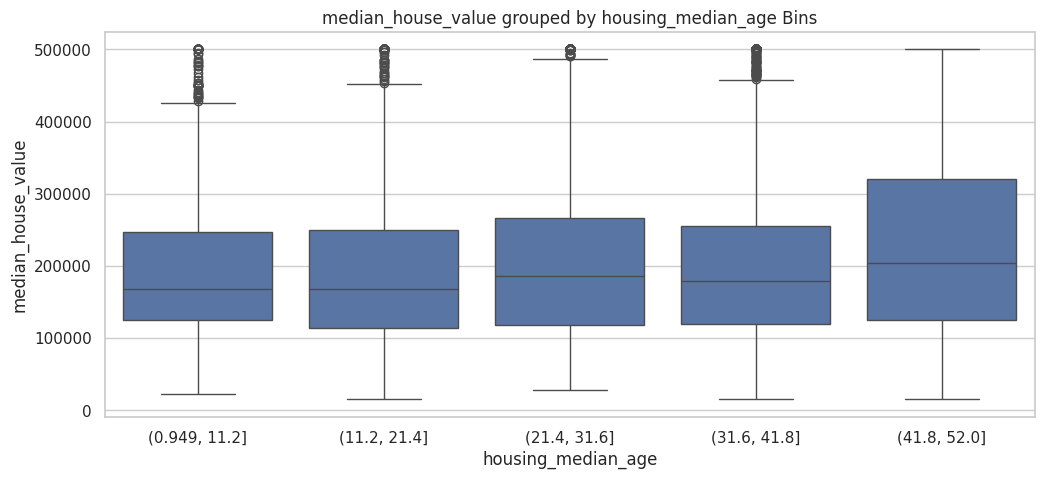

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Determine which target columns to use (House Prices vs. California Housing)
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"

# --- PLOT 1: 1 Row, 3 Columns for Target Distribution ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Axis 1: HISTOGRAM with KDE overlay
sns.histplot(df[target_col], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title(f"Distribution of {target_col}")
axes[0].set_xlabel(target_col)
axes[0].set_ylabel("Count")

# Axis 2: BOXPLOT
sns.boxplot(y=df[target_col], ax=axes[1], color="lightgreen")
axes[1].set_title(f"Boxplot of {target_col}")

# Axis 3: HISTOGRAM of LOG(Target)
log_target = np.log1p(df[target_col])
sns.histplot(log_target, kde=True, ax=axes[2], color="salmon")
axes[2].set_title(f"Distribution of Log({target_col})")
axes[2].set_xlabel(f"Log({target_col})")

plt.tight_layout()
plt.show()

# Compare skewness before and after log transform
original_skew = df[target_col].skew()
logged_skew = log_target.skew()
print(f"Skewness of original {target_col}: {original_skew:.4f}")
print(f"Skewness of Log({target_col}):     {logged_skew:.4f}")
print("-" * 80)

# --- PLOT 2 & 3: Categorical/Ordinal Groupings (Dynamic Check) ---
# If using Ames dataset, plot OverallQual & Neighborhood. Otherwise, adapt to California Housing.
if "OverallQual" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x="OverallQual", y=target_col, data=df)
    plt.title(f"{target_col} grouped by OverallQual")
    plt.show()
else:
    # Fallback to housing_median_age groups as a demonstration of discrete numeric values
    plt.figure(figsize=(12, 5))
    # Group ages into 5 bins to act as a pseudo discrete variable
    age_bins = pd.cut(df["housing_median_age"], bins=5)
    sns.boxplot(x=age_bins, y=df[target_col])
    plt.title(f"{target_col} grouped by housing_median_age Bins")
    plt.show()

if "Neighborhood" in df.columns:
    plt.figure(figsize=(14, 6))
    # Sort neighborhoods by median price
    sorted_neighborhoods = df.groupby("Neighborhood")[target_col].median().sort_values().index
    sns.boxplot(x="Neighborhood", y=target_col, data=df, order=sorted_neighborhoods)
    plt.title(f"{target_col} grouped by Neighborhood (Sorted by Median Price)")
    plt.xticks(rotation=90)
    plt.show()

# Countplots for Categorical/Ordinal variables if present
if "OverallQual" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x="OverallQual", data=df)
    plt.title("Count of OverallQual")
    plt.show()

if "HouseStyle" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x="HouseStyle", data=df)
    plt.title("Count of HouseStyle")
    plt.show()

Step 5: Correlation and Covariance
Goal: Find numerical features most related to price.

In [10]:
import pandas as pd
import numpy as np

# 1. Determine target column (Ames vs. California Housing)
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"
print(f"Using target column: {target_col}\n")

# 2. Subset numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# 3. Calculate Covariance and Correlation matrices
cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method='pearson')

# 4. Sort absolute correlations with the target column in descending order
top_corr = corr_matrix[target_col].abs().sort_values(ascending=False)

# Print top 10 features (including the target itself)
print("--- Top 10 Features Correlated with Target (Absolute Correlation) ---")
print(corr_matrix[target_col].loc[top_corr.index[:10]])
print("-" * 80)

# 5. For the top 3 features (excluding the target itself)
top_3_features = top_corr.index[1:4].tolist()
print(f"--- Detailed Stats for Top 3 Predictor Features: {top_3_features} ---")
for feature in top_3_features:
    cov_val = cov_matrix.loc[feature, target_col]
    corr_val = corr_matrix.loc[feature, target_col]
    print(f"{feature}:")
    print(f"  Covariance with {target_col}:  {cov_val:,.4f}")
    print(f"  Correlation with {target_col}: {corr_val:,.4f}\n")

print("-" * 80)
# 6. Explanation: Correlation vs Covariance
print("--- Why Correlation is Easier to Compare Than Covariance ---")
explanation = (
    "1. Scale Independence: Covariance depends entirely on the units of the variables\n"
    "   (e.g., dollar values vs. room counts). Its values can range from negative to positive infinity,\n"
    "   making it impossible to compare relationships between different pairs of features.\n"
    "2. Standardized Range: Correlation standardizes covariance to a range between -1 and +1.\n"
    "   This makes it intuitive to measure the exact strength and direction of the linear relationship\n"
    "   across completely different physical scales."
)
print(explanation)

# 7. OPTIONAL: Spearman correlation for ordinal columns if they exist in the dataset
ordinal_cols = [col for col in ["ExterQual", "KitchenQual"] if col in df.columns]
if ordinal_cols:
    print("\n" + "-" * 80)
    print("--- Spearman Rank Correlation for Ordinal Columns ---")
    for col in ordinal_cols:
        # Convert ordered categorical to numeric codes for correlation analysis
        spearman_corr, _ = stats.spearmanr(df[col].cat.codes, df[target_col])
        print(f"{col} vs {target_col} (Spearman Rank): {spearman_corr:.4f}")

Using target column: median_house_value

--- Top 10 Features Correlated with Target (Absolute Correlation) ---
median_house_value    1.000000
median_income         0.691871
latitude             -0.144917
total_rooms           0.130991
housing_median_age    0.106758
households            0.061031
total_bedrooms        0.045783
longitude            -0.044982
population           -0.027850
Name: median_house_value, dtype: float64
--------------------------------------------------------------------------------
--- Detailed Stats for Top 3 Predictor Features: ['median_income', 'latitude', 'total_rooms'] ---
median_income:
  Covariance with median_house_value:  153,121.4645
  Correlation with median_house_value: 0.6919

latitude:
  Covariance with median_house_value:  -35,924.3782
  Correlation with median_house_value: -0.1449

total_rooms:
  Covariance with median_house_value:  33,119,681.5846
  Correlation with median_house_value: 0.1310

---------------------------------------------------

Step 6: Scatter Plots and Pair Plots
Goal: Visualise relationships and spot unusual points.

Using mappings: x1=total_rooms, x2=total_bedrooms, x3=housing_median_age, y=median_house_value


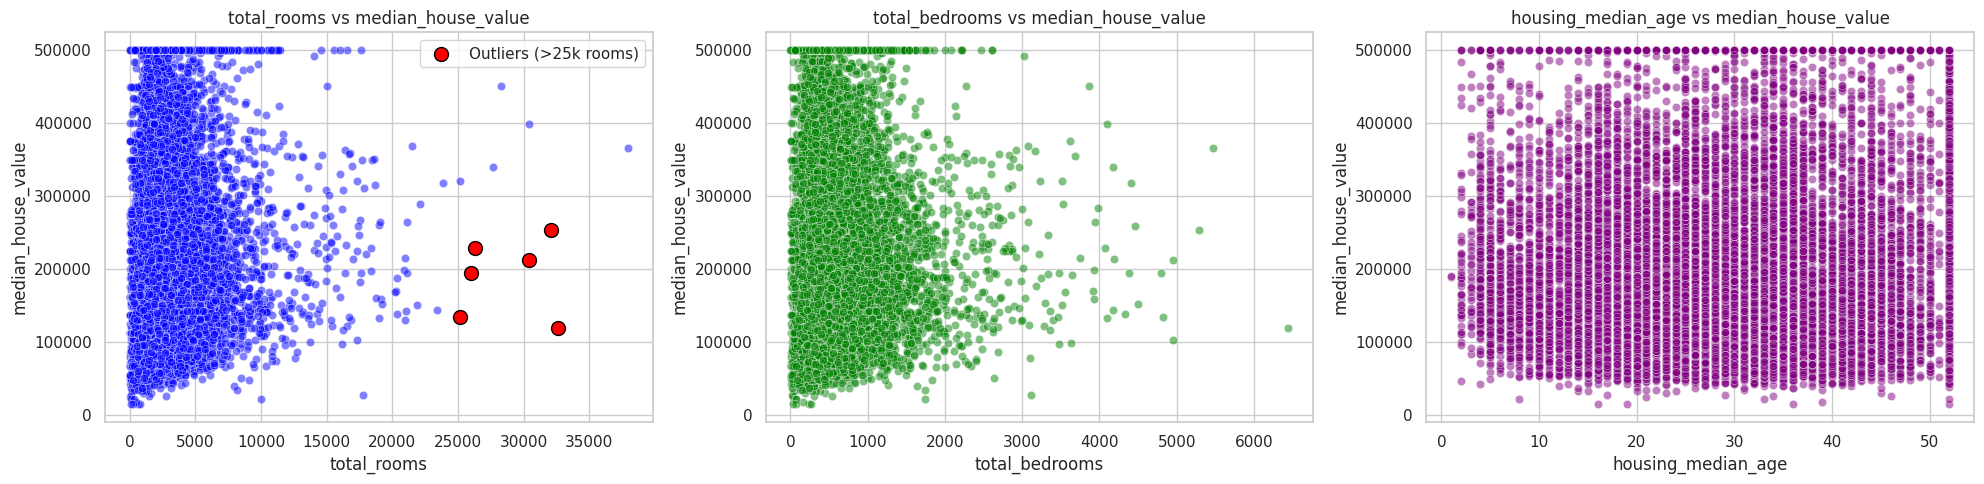

Generating Pairplot for selected variables...


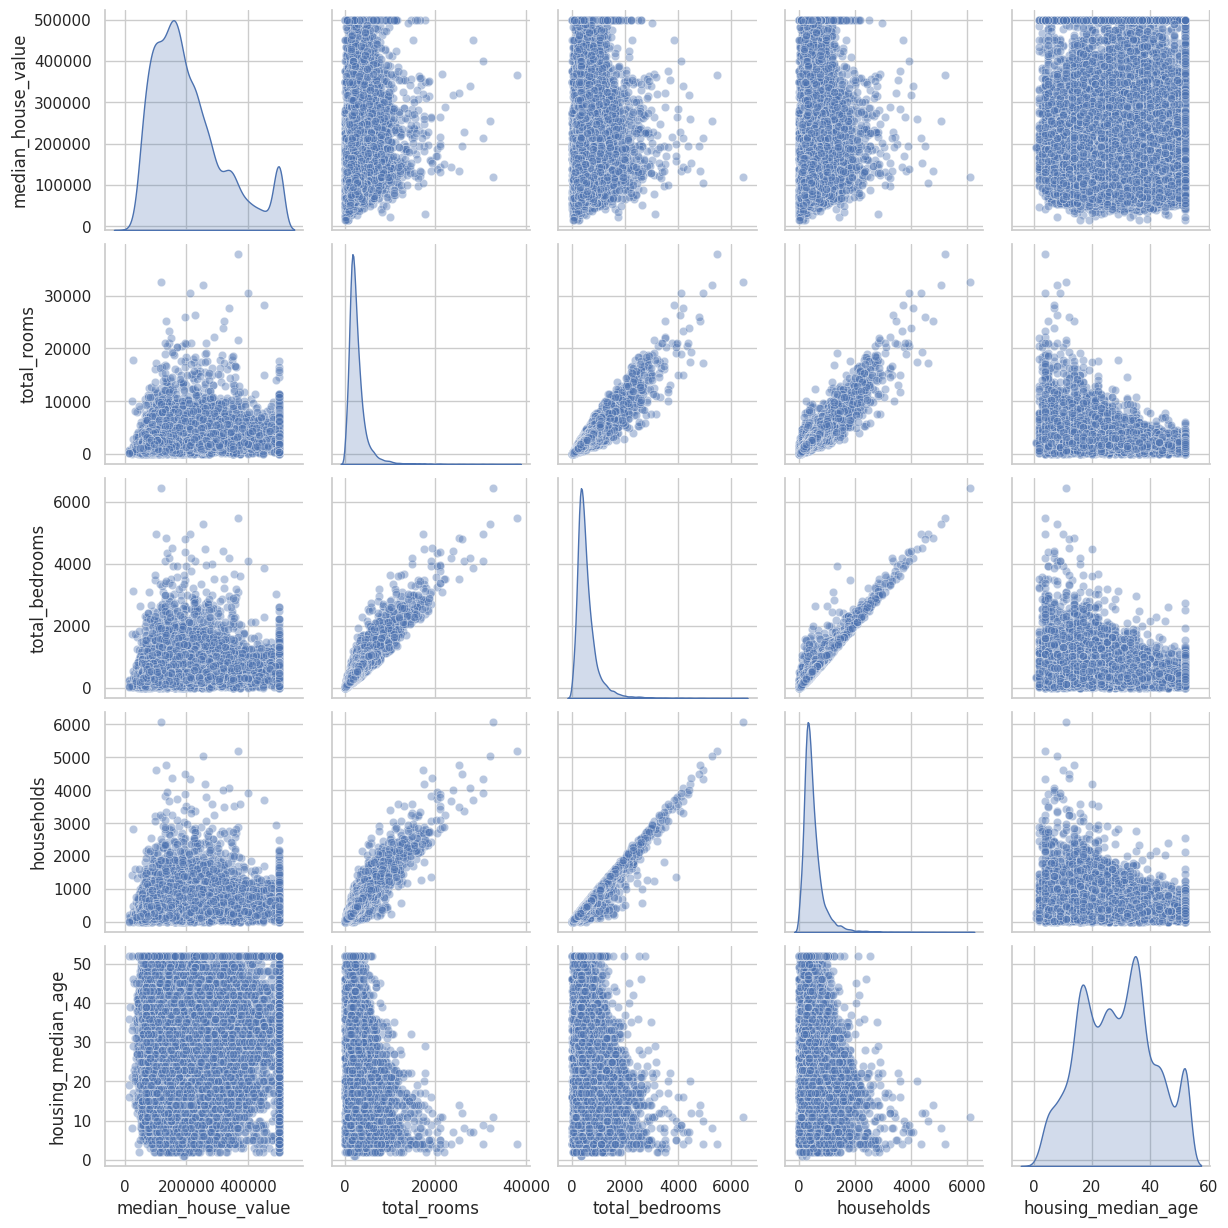

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Determine dataset columns (Ames vs. California Housing equivalents)
if "SalePrice" in df.columns:
    x1, y1 = "GrLivArea", "SalePrice"
    x2, y2 = "TotalBsmtSF", "SalePrice"
    x3, y3 = "YearBuilt", "SalePrice"
    selected_cols = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
    hue_col = "CentralAir" if "CentralAir" in df.columns else None
else:
    # Fallbacks for California Housing dataset
    x1, y1 = "total_rooms", "median_house_value"
    x2, y2 = "total_bedrooms", "median_house_value"
    x3, y3 = "housing_median_age", "median_house_value"
    selected_cols = ["median_house_value", "total_rooms", "total_bedrooms", "households", "housing_median_age"]
    hue_col = None

print(f"Using mappings: x1={x1}, x2={x2}, x3={x3}, y={y1}")

# 2. Scatter Plots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Scatter Plot 1: x1 vs y1
sns.scatterplot(data=df, x=x1, y=y1, ax=axes[0], alpha=0.5, color="blue")
axes[0].set_title(f"{x1} vs {y1}")
axes[0].set_xlabel(x1)
axes[0].set_ylabel(y1)

# Highlight outliers (e.g., extremely high room count but low/modest price)
if x1 == "GrLivArea":
    outliers = df[(df[x1] > 4000) & (df[y1] < 300000)]
    if not outliers.empty:
        axes[0].scatter(outliers[x1], outliers[y1], color="red", edgecolor="black", s=100, label="Outliers")
        axes[0].legend()
elif x1 == "total_rooms":
    # Adapt outlier highlighting for California dataset (e.g., total_rooms > 25000)
    outliers = df[(df[x1] > 25000) & (df[y1] < 300000)]
    if not outliers.empty:
        axes[0].scatter(outliers[x1], outliers[y1], color="red", edgecolor="black", s=100, label="Outliers (>25k rooms)")
        axes[0].legend()

# Scatter Plot 2: x2 vs y2
sns.scatterplot(data=df, x=x2, y=y2, ax=axes[1], alpha=0.5, color="green")
axes[1].set_title(f"{x2} vs {y2}")
axes[1].set_xlabel(x2)
axes[1].set_ylabel(y2)

# Scatter Plot 3: x3 vs y3
sns.scatterplot(data=df, x=x3, y=y3, ax=axes[2], alpha=0.5, color="purple")
axes[2].set_title(f"{x3} vs {y3}")
axes[2].set_xlabel(x3)
axes[2].set_ylabel(y3)

plt.tight_layout()
plt.show()

# 3. Pairplot
print("Generating Pairplot for selected variables...")
available_selected = [col for col in selected_cols if col in df.columns]

sns.pairplot(df[available_selected], diag_kind="kde", hue=hue_col, plot_kws={'alpha': 0.4})
plt.show()

Step 7: Correlation Heatmap
Goal: One clear picture of feature relationships.

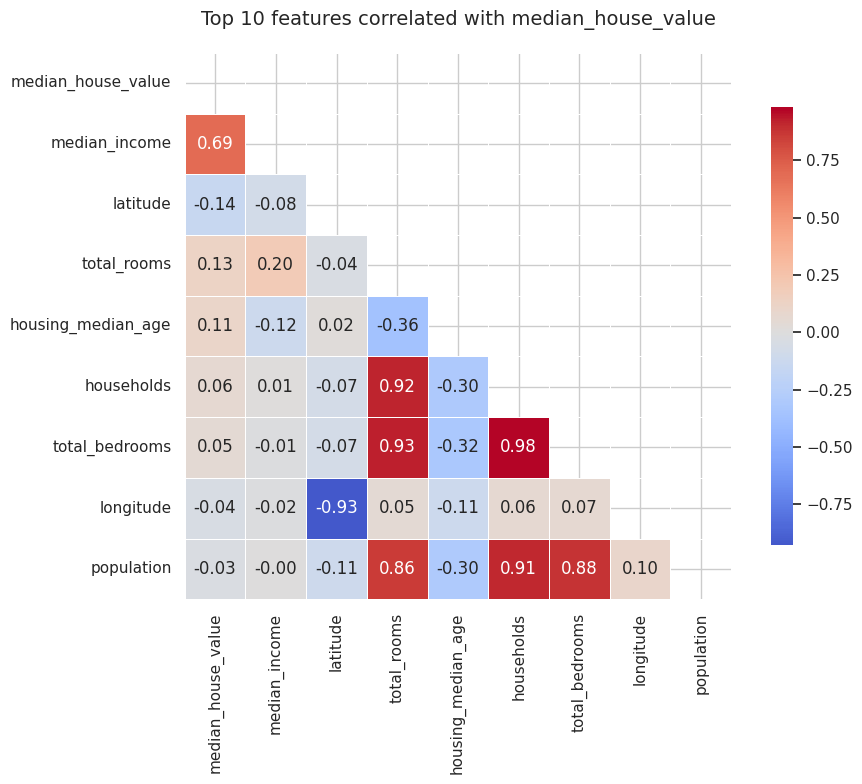

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Determine target column (Ames vs. California Housing equivalents)
target_col = "SalePrice" if "SalePrice" in df.columns else "median_house_value"

# 2. Get numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# 3. Find top 10 features most correlated with target
full_corr = numeric_df.corr(method='pearson')
top10_idx = full_corr[target_col].abs().sort_values(ascending=False).index[:10]
top10_cols = list(top10_idx)

# 4. Compute correlation of top 10 features
corr_top10 = numeric_df[top10_cols].corr(method='pearson')

# 5. Create a mask to hide the upper triangle of the matrix (duplicate half)
mask = np.triu(np.ones_like(corr_top10, dtype=bool))

# 6. Render the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_top10,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title(f"Top 10 features correlated with {target_col}", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

Step 8: Outlier Detection
Goal: Detect outliers with two methods and compare.

Target columns not found. Standardizing to California Housing columns: ['total_rooms', 'median_house_value']

=== Outlier Detection for: total_rooms ===
IQR Method Count (1.5 IQR): 1076
Z-score Method Count (Threshold=3): 313
Overlap (identified by both): 313

=== Outlier Detection for: median_house_value ===
IQR Method Count (1.5 IQR): 895
Z-score Method Count (Threshold=3): 0
Overlap (identified by both): 0



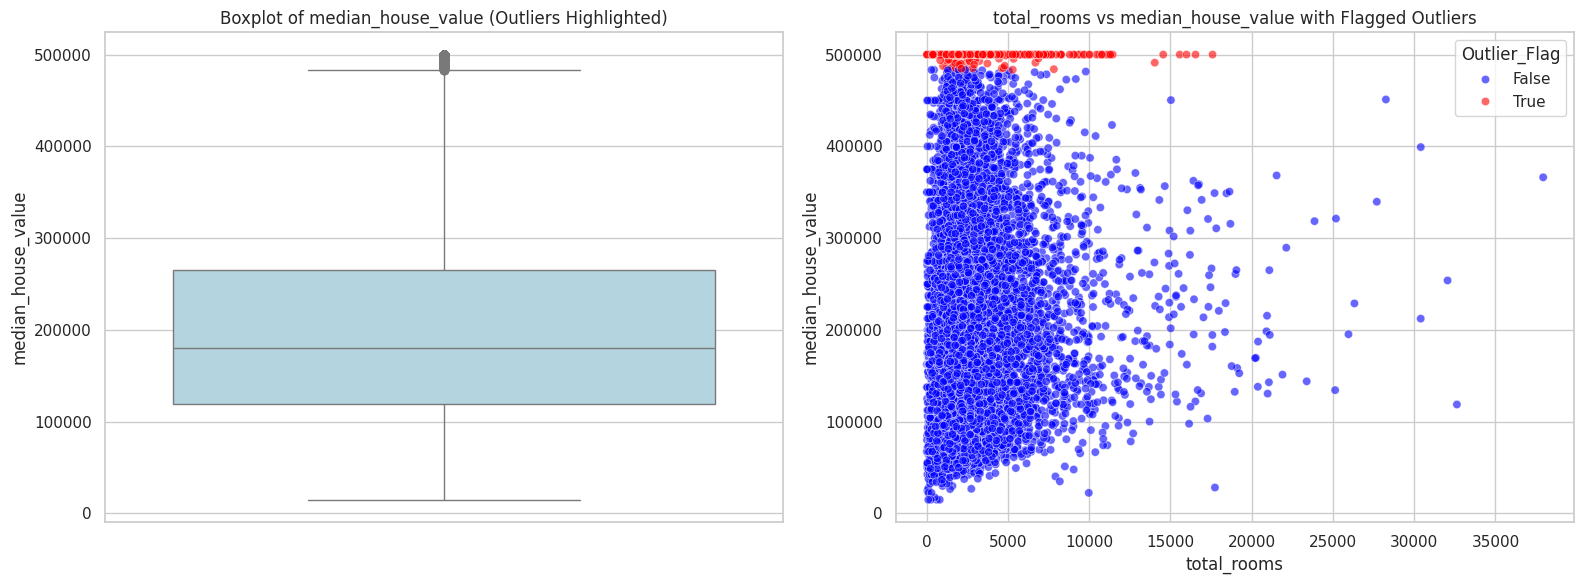

=== OUTLIER DECISION ANALYSIS ===
Based on the plots:
1. If we see a hard ceiling of values (e.g., at 500,001 in California Housing) or extreme isolated values,
   these are likely data caps or non-typical points that might affect linear models.
2. Action: You can choose to create a filtered dataframe by dropping extremely high value points, 
   or keep them and model using robust algorithms. Let's create a cleaned dataset excluding extreme values:
Original dataset shape: (17000, 9)
Cleaned dataset shape (removed 0 consensus target outliers): (17000, 9)


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define outlier detection functions
def detect_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return series[(series < lower_bound) | (series > upper_bound)]

def detect_zscore_outliers(series, threshold=3):
    z_scores = (series - series.mean()) / series.std()
    return series[z_scores.abs() > threshold]

# 2. Determine columns to analyze (Ames vs. California Housing equivalents)
cols_to_analyze = ["GrLivArea", "SalePrice"]
if not all(col in df.columns for col in cols_to_analyze):
    cols_to_analyze = ["total_rooms", "median_house_value"]
    print(f"Target columns not found. Standardizing to California Housing columns: {cols_to_analyze}\n")

x_col, y_col = cols_to_analyze[0], cols_to_analyze[1]

# 3. Analyze outliers and calculate overlaps
for col in cols_to_analyze:
    iqr_outliers = detect_iqr_outliers(df[col])
    z_outliers = detect_zscore_outliers(df[col], threshold=3)

    overlap = set(iqr_outliers.index).intersection(set(z_outliers.index))

    print(f"=== Outlier Detection for: {col} ===")
    print(f"IQR Method Count (1.5 IQR): {len(iqr_outliers)}")
    print(f"Z-score Method Count (Threshold=3): {len(z_outliers)}")
    print(f"Overlap (identified by both): {len(overlap)}\n")

# Flag rows as outliers if detected by either method on the target column (Y)
y_iqr_idx = detect_iqr_outliers(df[y_col]).index
y_z_idx = detect_zscore_outliers(df[y_col]).index
all_y_outliers = set(y_iqr_idx).union(set(y_z_idx))

df_flagged = df.copy()
df_flagged['Outlier_Flag'] = df_flagged.index.isin(all_y_outliers)

# 4. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Boxplot of Target with Outliers
sns.boxplot(data=df, y=y_col, ax=axes[0], color="lightblue")
axes[0].set_title(f"Boxplot of {y_col} (Outliers Highlighted)")

# Right Plot: Scatter Plot highlighting detected outliers
sns.scatterplot(data=df_flagged, x=x_col, y=y_col, hue='Outlier_Flag', palette={False: 'blue', True: 'red'}, alpha=0.6, ax=axes[1])
axes[1].set_title(f"{x_col} vs {y_col} with Flagged Outliers")
axes[1].set_xlabel(x_col)
axes[1].set_ylabel(y_col)

plt.tight_layout()
plt.show()

# 5. Outlier Decision Logic
print("=== OUTLIER DECISION ANALYSIS ===")
print("Based on the plots:")
print(f"1. If we see a hard ceiling of values (e.g., at 500,001 in California Housing) or extreme isolated values,")
print("   these are likely data caps or non-typical points that might affect linear models.")
print("2. Action: You can choose to create a filtered dataframe by dropping extremely high value points, ")
print("   or keep them and model using robust algorithms. Let's create a cleaned dataset excluding extreme values:")

# Let's filter out extreme target outliers detected by both methods
both_methods_outliers = set(y_iqr_idx).intersection(set(y_z_idx))
df_clean = df.drop(index=list(both_methods_outliers))
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape (removed {len(both_methods_outliers)} consensus target outliers): {df_clean.shape}")

Step 9: Data Quality Checks
Goal: Find duplicates, inconsistent labels, and misleading missing values.

In [18]:
import pandas as pd
import numpy as np

# 1. Duplicated Rows Check
dup_count = df.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates()
    print(f"Duplicates removed. New dataset shape: {df.shape}")
else:
    print("No duplicated rows found.")
print("-" * 80)

# 2. Categorical Column Consistency Check
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
if categorical_cols:
    print("Checking categorical column values for inconsistencies...")
    for col in categorical_cols:
        # Convert elements to string to safely check casing / spacing
        unique_vals = df[col].dropna().astype(str).unique()
        print(f"Column '{col}' unique values: {unique_vals[:10]}")

        # Example standardization routine
        df[col] = df[col].astype(str).str.strip().str.lower()
else:
    print("No categorical columns found in the current dataset to standardize.")
print("-" * 80)

# 3. Handle Special Missing Code replacements (Ames specific columns)
special_null_cols = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]
existing_special_cols = [col for col in special_null_cols if col in df.columns]
if existing_special_cols:
    print(f"Replacing missing indicators for special categorical fields: {existing_special_cols}")
    for col in existing_special_cols:
        df[col] = df[col].fillna("None")
else:
    print("No special categorical missing-value indicator columns (like Alley, PoolQC) exist in this dataset.")
print("-" * 80)

# 4. Numeric Missing Value Imputation
numeric_missing = df.select_dtypes(include=[np.number]).isnull().sum()
numeric_missing = numeric_missing[numeric_missing > 0]

if not numeric_missing.empty:
    print("Imputing missing numeric values...")
    for col in numeric_missing.index:
        # Check if we can group by Neighborhood, otherwise use global median
        if "Neighborhood" in df.columns:
            df[col] = df.groupby("Neighborhood")[col].transform(lambda x: x.fillna(x.median()))
            print(f"Filled missing values in '{col}' using Neighborhood median.")
        else:
            col_median = df[col].median()
            df[col] = df[col].fillna(col_median)
            print(f"Filled missing values in '{col}' using global median: {col_median}")
else:
    print("No missing numeric values to impute.")
print("-" * 80)

# 5. Verify remaining missing count
remaining_missing = df.isnull().sum().sum()
print(f"Verification: Total remaining missing values in DataFrame = {remaining_missing}")
print("-" * 80)

# 6. Check for impossible/illogical value constraints
print("Checking data for physical/logical anomalies...")
anomalies_found = False

# Check 1: Negative areas / values
for col in ["total_rooms", "total_bedrooms", "population", "households", "median_house_value", "median_income"]:
    if col in df.columns:
        negatives = df[df[col] < 0]
        if not negatives.empty:
            print(f"ALERT: Found {len(negatives)} negative values in column '{col}'!")
            anomalies_found = True

# Check 2: Logical bounds (e.g. Bedrooms greater than Rooms)
if "total_bedrooms" in df.columns and "total_rooms" in df.columns:
    impossible_rooms = df[df["total_bedrooms"] > df["total_rooms"]]
    if not impossible_rooms.empty:
        print(f"ALERT: Found {len(impossible_rooms)} rows where total_bedrooms exceeds total_rooms!")
        anomalies_found = True

# Check 3: Construction/Sale bounds for Ames dataset
if "YearBuilt" in df.columns and "YrSold" in df.columns:
    impossible_years = df[df["YearBuilt"] > df["YrSold"]]
    if not impossible_years.empty:
        print(f"ALERT: Found {len(impossible_years)} rows where YearBuilt is newer than YrSold!")
        anomalies_found = True

if not anomalies_found:
    print("Data Quality Checks Complete: No logical anomalies or impossible values detected!")

Number of duplicated rows: 0
No duplicated rows found.
--------------------------------------------------------------------------------
No categorical columns found in the current dataset to standardize.
--------------------------------------------------------------------------------
No special categorical missing-value indicator columns (like Alley, PoolQC) exist in this dataset.
--------------------------------------------------------------------------------
No missing numeric values to impute.
--------------------------------------------------------------------------------
Verification: Total remaining missing values in DataFrame = 0
--------------------------------------------------------------------------------
Checking data for physical/logical anomalies...
Data Quality Checks Complete: No logical anomalies or impossible values detected!


Step 10: Final Dashboard and Storytelling
Goal: Combine the best visuals into one clean figure and write conclusions.

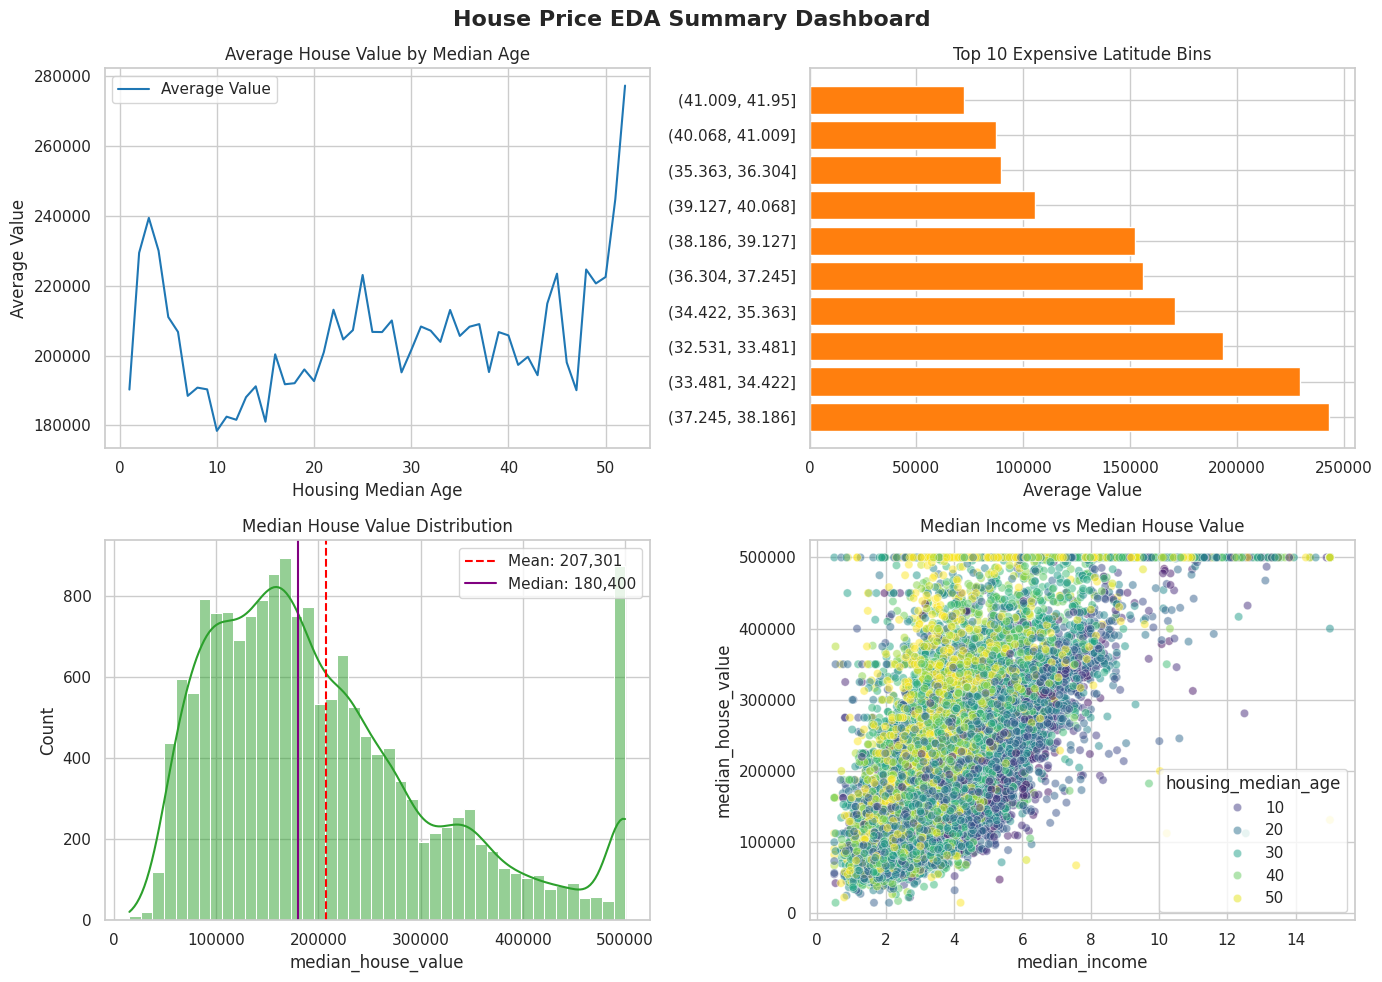

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Set seaborn theme style
sns.set_theme(style="whitegrid")

# Create 2x2 figure dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Determine active dataset target columns
if "SalePrice" in df.columns:
    # Ames dataset mappings
    # Panel 1
    grouped_yr = df.groupby("YearBuilt")["SalePrice"].mean().reset_index()
    axes[0, 0].plot(grouped_yr["YearBuilt"], grouped_yr["SalePrice"], color="tab:blue", label="Average Price")
    axes[0, 0].set_title("Average SalePrice by Year Built")
    axes[0, 0].set_xlabel("Year Built")
    axes[0, 0].set_ylabel("Average Price")
    axes[0, 0].legend()

    # Panel 2
    grouped_neigh = df.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=False).head(10)
    axes[0, 1].barh(grouped_neigh.index, grouped_neigh.values, color="tab:orange")
    axes[0, 1].set_title("Top 10 Expensive Neighborhoods")
    axes[0, 1].set_xlabel("Average Price")

    # Panel 3
    sns.histplot(df["SalePrice"], kde=True, ax=axes[1, 0], color="tab:green")
    mean_price = df["SalePrice"].mean()
    median_price = df["SalePrice"].median()
    axes[1, 0].axvline(mean_price, color="red", linestyle="--", label=f"Mean: {mean_price:,.0f}")
    axes[1, 0].axvline(median_price, color="purple", linestyle="-", label=f"Median: {median_price:,.0f}")
    axes[1, 0].set_title("SalePrice Distribution")
    axes[1, 0].legend()

    # Panel 4
    sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", ax=axes[1, 1], alpha=0.6)
    axes[1, 1].set_title("GrLivArea vs SalePrice")

else:
    # California Housing equivalents
    # Panel 1
    grouped_age = df.groupby("housing_median_age")["median_house_value"].mean().reset_index()
    axes[0, 0].plot(grouped_age["housing_median_age"], grouped_age["median_house_value"], color="tab:blue", label="Average Value")
    axes[0, 0].set_title("Average House Value by Median Age")
    axes[0, 0].set_xlabel("Housing Median Age")
    axes[0, 0].set_ylabel("Average Value")
    axes[0, 0].legend()

    # Panel 2 (Group by latitude bins as a regional 'neighborhood' proxy)
    df["lat_bin"] = pd.cut(df["latitude"], bins=10).astype(str)
    grouped_lat = df.groupby("lat_bin")["median_house_value"].mean().sort_values(ascending=False).head(10)
    axes[0, 1].barh(grouped_lat.index, grouped_lat.values, color="tab:orange")
    axes[0, 1].set_title("Top 10 Expensive Latitude Bins")
    axes[0, 1].set_xlabel("Average Value")

    # Panel 3
    sns.histplot(df["median_house_value"], kde=True, ax=axes[1, 0], color="tab:green")
    mean_val = df["median_house_value"].mean()
    median_val = df["median_house_value"].median()
    axes[1, 0].axvline(mean_val, color="red", linestyle="--", label=f"Mean: {mean_val:,.0f}")
    axes[1, 0].axvline(median_val, color="purple", linestyle="-", label=f"Median: {median_val:,.0f}")
    axes[1, 0].set_title("Median House Value Distribution")
    axes[1, 0].legend()

    # Panel 4
    sns.scatterplot(data=df, x="median_income", y="median_house_value", hue="housing_median_age", palette="viridis", ax=axes[1, 1], alpha=0.5)
    axes[1, 1].set_title("Median Income vs Median House Value")

fig.suptitle("House Price EDA Summary Dashboard", fontsize=16, weight="bold")
plt.tight_layout()

# Save the dashboard as a PNG
plt.savefig("eda_dashboard.png", dpi=300)
plt.show()